# ЛР2: базовая модель для SMS Spam Collection

Ноутбук запускается из `~/ml-project/notebooks`. Предобработка и модель находятся в `src/`.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))
import pandas as pd
import matplotlib.pyplot as plt
from src.data_utils import load_and_check
from src.train import train_and_evaluate

df, info = load_and_check(Path("../data/SMSSpamCollection"))
print(info)
display(df.head())
display(df.isna().sum())
display(df["label"].value_counts())

{'dataset_path': '../data/SMSSpamCollection', 'dataset_sha256': '7d039a24a6083ed9ef0f806ebad56bbb976e3aeb8de05669173bfdc4996c239d', 'original_rows': 5572, 'duplicates_removed': 415, 'conflicting_label_rows_removed': 0, 'remaining_rows': 5157, 'class_counts': {'ham': 4515, 'spam': 642}, 'missing_values': 0, 'empty_messages': 0, 'label_values': ['ham', 'spam'], 'feature_types': {'message': 'string', 'label': 'string'}}


,label,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


label      0
message    0
dtype: int64

label
ham     4515
spam     642
Name: count, dtype: Int64

## Распределение классов

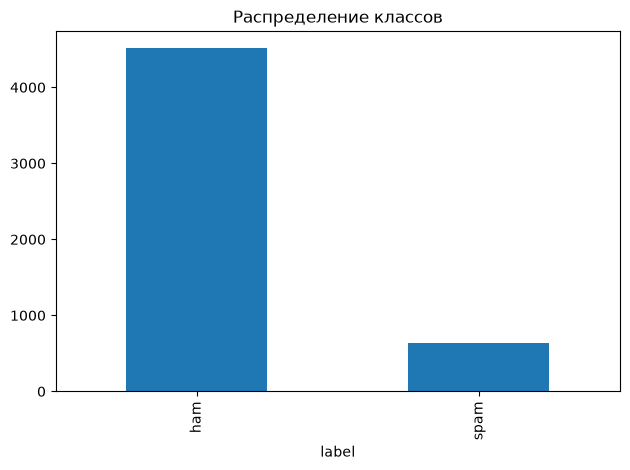

In [2]:
df["label"].value_counts().plot.bar(title="Распределение классов")
plt.tight_layout()
plt.show()

## Обучение и оценка

Вызов из модуля `src/train.py` гарантирует ту же обучающую процедуру и разделение 80/20, seed=42. Файлы `metrics/baseline.json` и `models/spam_pipeline.joblib` создаются в корне проекта.

In [3]:
import os
os.chdir("..")
results = train_and_evaluate()
os.chdir("notebooks")
print("Основная метрика (F1 spam):", results["primary_metric_value"])
print("Сравнение с DummyClassifier:", results["most_frequent_baseline"])

Загруженная модель отвечает: spam
Проверка данных: {'dataset_path': 'data/SMSSpamCollection', 'dataset_sha256': '7d039a24a6083ed9ef0f806ebad56bbb976e3aeb8de05669173bfdc4996c239d', 'original_rows': 5572, 'duplicates_removed': 415, 'conflicting_label_rows_removed': 0, 'remaining_rows': 5157, 'class_counts': {'ham': 4515, 'spam': 642}, 'missing_values': 0, 'empty_messages': 0, 'label_values': ['ham', 'spam'], 'feature_types': {'message': 'string', 'label': 'string'}}
Метрики: {
  "accuracy": 0.9786821705426356,
  "precision_spam": 0.8955223880597015,
  "recall_spam": 0.9375,
  "f1_spam": 0.916030534351145,
  "per_class": {
    "ham": {
      "precision": 0.9910913140311804,
      "recall": 0.9845132743362832,
      "f1": 0.9877913429522752
    },
    "spam": {
      "precision": 0.8955223880597015,
      "recall": 0.9375,
      "f1": 0.916030534351145
    }
  }
}
Простой baseline: {
  "accuracy": 0.875968992248062,
  "precision_spam": 0.0,
  "recall_spam": 0.0,
  "f1_spam": 0.0,
  "per_cl

## Матрица ошибок и анализ ошибок

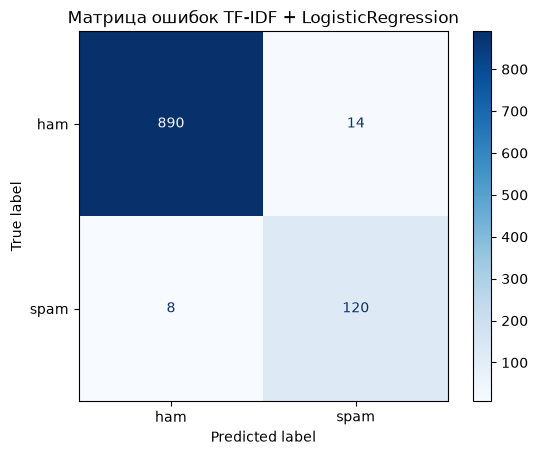

,message,label,prediction
0,"Sir, i am waiting for your call, once free ple...",ham,spam
1,I'm at home. Please call,ham,spam
2,Sorry I missed your call let's talk when you h...,spam,ham
3,I'm at work. Please call,ham,spam
4,Glad to see your reply.,ham,spam


In [4]:
from sklearn.metrics import ConfusionMatrixDisplay
import numpy as np
m = np.array(results["confusion_matrix"])
ConfusionMatrixDisplay(m, display_labels=results["confusion_matrix_labels"]).plot(cmap="Blues")
plt.title("Матрица ошибок TF-IDF + LogisticRegression")
plt.show()
errors = pd.read_csv("../metrics/errors_private.csv")
# Примеры предназначены только для локального анализа; не выкладывать SMS в публичный отчет без проверки.
display(errors.head(5))

## Вывод

В отчёте укажите реальные Accuracy, Precision/Recall/F1 по классам, сравнение с DummyClassifier, несколько ошибочных классификаций (без разглашения персональных данных), дисбаланс и ограничения датасета. Не подбирайте параметры модели по тестовой выборке.